In [1]:
# Imports
import pandas as pd
import numpy as np
import faiss

In [2]:
# kNN via FAISS: L2 on L2-normalized vectors (= cosine); returns each paper's k nearest neighbours
def knn_faiss(df,k):
    paper_ids = df['project_id'].values
    embeddings_cols = [col for col in df.columns if col!='project_id']
    X = df[embeddings_cols].values.astype('float32')

    #L2 Normalization
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    X = X/np.clip(norms,1e-12,None)
    d = X.shape[1]
    index = faiss.IndexFlatL2(d)
    index.add(X)
    print(f"FAISS index built with {index.ntotal} vectors of dimension {d}")

    distance ,indices= index.search(X, k+1)  # k+1 because the closest vector is itself
    
    # Build knn_sets with actual project IDs
    knn_dict = {}
    for i in range(len(paper_ids)):
        neighbors = indices[i][1:]  # Exclude the first one (itself)
        neighbors = neighbors[neighbors >= 0]  # Filter out invalid indices (-1)
        knn_dict[paper_ids[i]] = [paper_ids[n] for n in neighbors]
    
    # Find mutual edges using indices
    knn_sets = {}
    for i in range(len(paper_ids)):
        neighbors = indices[i][1:]
        neighbors = neighbors[neighbors >= 0]
        knn_sets[i] = set(neighbors)
    
    mutual_edges = []
    for i in range(len(paper_ids)):
        for j in knn_sets[i]:
            if i in knn_sets[j]:  # Check for mutual nearest neighbor
                mutual_edges.append((i,j))
    mutual_edges = list(set(tuple(sorted(edge)) for edge in mutual_edges))  # Remove duplicates
    mutual_edge_ids = [(paper_ids[i], paper_ids[j]) for i,j in mutual_edges]
    
    return knn_dict, mutual_edge_ids

In [3]:
#example usage make a dummy df
# data = {
#     'project_id': ['p1', 'p2', 'p3', 'p4'],
#     'emb1': [0.1, 0.2, 0.3, 0.4],
#     'emb2': [0.5, 0.6, 0.7, 0.8],
#     'emb3': [0.9, 1.0, 1.1, 1.2]
# }
# df = pd.DataFrame(data)
df = pd.read_csv(r"data/scibert_embeddings.csv").drop(columns=['original_id_clean'])  
k = 20
N=len(df)
neighbors, mutual_edges = knn_faiss(df, k)
# print("Neighbors:")
# print(neighbors)
# print("\nMutual edges:")
# print(mutual_edges)

FAISS index built with 131772 vectors of dimension 768


In [4]:
# Degree statistics of the mutual-kNN graph
from collections import Counter
degree = Counter()
for u,v in mutual_edges:
    degree[u]+=1
    degree[v]+=1
print("Mean degree",np.mean(list(degree.values())))
print("Max degree",max(degree.values()))
print("Min degree",min(degree.values()))
print("Median degree",np.median(list(degree.values())))

Mean degree 6.828181479260208
Max degree 21
Min degree 1
Median degree 6.0


In [5]:
# Identify hub nodes (top 1% by degree)
degree_values = list(degree.values())
hub_threshold = np.percentile(degree_values, 99)
hub_nodes = [node for node, deg in degree.items() if deg > hub_threshold]
print(f"Number of hub nodes (degree > {hub_threshold}): {len(hub_nodes)}")

Number of hub nodes (degree > 19.0): 684


In [6]:
# Count isolated nodes (degree 0)
isolated_nodes = [node for node, deg in degree.items() if deg == 0]
print(f"Number of isolated nodes (degree = 0): {len(isolated_nodes)}")
print("Isolated fraction:", len(isolated_nodes)/N)

Number of isolated nodes (degree = 0): 0
Isolated fraction: 0.0


In [7]:
# Connected components of the graph
import networkx as nx
G = nx.Graph()
G.add_nodes_from(range(N))
G.add_edges_from(mutual_edges)
components = list(nx.connected_components(G))
print(f"Number of connected components: {len(components)}")
component_sizes = [len(c) for c in components]
print("Largest Component size:", max(component_sizes))
print("Largest component fraction:", max(component_sizes)/N)

Number of connected components: 24660
Largest Component size: 121798
Largest component fraction: 0.9243086543423489


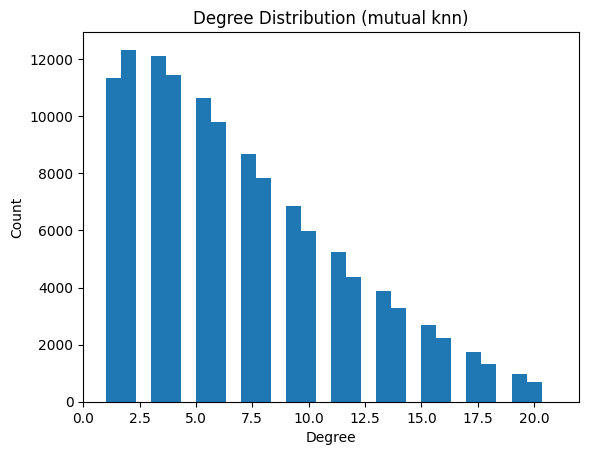

In [8]:
# Plot the degree distribution
import matplotlib.pyplot as plt
plt.hist(degree_values, bins=30)
plt.title("Degree Distribution (mutual knn)")
plt.xlabel("Degree")
plt.ylabel("Count")
plt.show()  

In [9]:
# np.save(f'kg/mutual_edges_scibert@{k}.npy', mutual_edges)